# CNN de clasificacion de danos v3

Cambios respecto de `cnn_damage_classification_multiclass_training.ipynb` (v2):
1. **Label smoothing** (0,1): la etiqueta deja de ser "100 % esta clase" y pasa a 90 % + 10 % repartido.
   Evita que el modelo diga 99 % para todo.
2. **Class weights suavizados**: raiz cuadrada de los pesos "balanced". Siguen ayudando a las clases chicas, pero
   empujan menos hacia ellas (la v2 mandaba 400 fotos de Surface flaking a Delamination).
3. **Calibracion** con *temperature scaling* sobre validacion, guardada en
   `models/modelo_clasificacion3_calibracion.json` para que el backend la use.
4. La evaluacion agrega el **ECE** (error de calibracion) y un diagrama de confiabilidad.

Mismos datos, mismo split (random_state=42), misma arquitectura (EfficientNetB0) y mismas dos fases.
No pisa la v2: guarda en `modelo_clasificacion3.keras`.

In [1]:
# Celda 1: imports, seeds y carga del dataset final
# Igual que la v2: necesita data_clasificacion/dataset_final.csv y
# grupos_final.json. Los genera descargar_datos_clasificacion3.ipynb
# (correrlo antes, una sola vez).

import os
import json
import random

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

LOCAL_DATA_DIR = "../data_clasificacion"  # los datos quedan en notebooks/, fuera de parte3
LABEL_SMOOTHING = 0.1
MODEL_PATH = "../../models/modelo_clasificacion3.keras"
CALIB_PATH = "../../models/modelo_clasificacion3_calibracion.json"

df = pd.read_csv(f"{LOCAL_DATA_DIR}/dataset_final.csv")
# las rutas del csv son relativas a notebooks/; este notebook esta en notebooks/parte3
df["image_path"] = "../" + df["image_path"]
with open(f"{LOCAL_DATA_DIR}/grupos_final.json") as f:
    GRUPOS_FINAL = json.load(f)

FINAL_CLASSES = list(GRUPOS_FINAL)
N_CLASES = len(FINAL_CLASSES)
clase_a_idx = {cls: i for i, cls in enumerate(FINAL_CLASSES)}
df["label_idx"] = df["label"].map(clase_a_idx)
print(f"Imagenes: {len(df)} | Clases: {N_CLASES}")

Imagenes: 39497 | Clases: 11


In [2]:
# Celda 2: split train/val/test (70/15/15)
# Exactamente el mismo que la v2 (random_state=42), asi los resultados se
# pueden comparar uno a uno.

train_df, resto_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(resto_df, test_size=0.50, stratify=resto_df["label"], random_state=42)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")

train: 27647 | val: 5925 | test: 5925


In [3]:
# Celda 3: class weights suavizados
# Parte de los pesos "balanced" de la v2 y les aplica raiz cuadrada.
# Ejemplo: Vandalism pasa de 3.51 a ~1.87 y Structural crack de 0.54 a ~0.73.
# Despues se normalizan para que el promedio ponderado sea 1 (no cambia la
# escala de la loss).

pesos_balanced = compute_class_weight("balanced", classes=np.arange(N_CLASES), y=train_df["label_idx"].values)
pesos = np.sqrt(pesos_balanced)
frecuencia = np.bincount(train_df["label_idx"], minlength=N_CLASES) / len(train_df)
pesos = pesos / np.sum(pesos * frecuencia)
class_weights = {i: float(p) for i, p in enumerate(pesos)}

for i, cls in enumerate(FINAL_CLASSES):
    print(f"  {cls:30s} balanced {pesos_balanced[i]:.2f} -> suavizado {pesos[i]:.2f}")

  Structural crack               balanced 0.54 -> suavizado 0.77
  Surface flaking/exfoliation    balanced 0.54 -> suavizado 0.77
  Salt weathering                balanced 1.45 -> suavizado 1.26
  Material loss/erosion          balanced 2.68 -> suavizado 1.72
  Moisture/water damage          balanced 0.98 -> suavizado 1.04
  Biological growth              balanced 2.61 -> suavizado 1.70
  Corrosion                      balanced 0.54 -> suavizado 0.77
  Concrete spalling              balanced 1.80 -> suavizado 1.41
  Vegetation                     balanced 0.72 -> suavizado 0.89
  Delamination                   balanced 1.34 -> suavizado 1.21
  Vandalism                      balanced 3.52 -> suavizado 1.97


In [4]:
# Celda 4: pipeline de imagenes con tf.data
# Igual que la v2, salvo que las etiquetas van en one-hot: el label
# smoothing de Keras necesita CategoricalCrossentropy (no la "sparse").

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, tf.one_hot(label, N_CLASES)

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
])

def make_dataset(dataframe, training):
    paths = dataframe["image_path"].values
    labels = dataframe["label_idx"].values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(2000, seed=42)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

In [5]:
# Celda 5: modelo
# Misma arquitectura que la v2. Cambia la loss: CategoricalCrossentropy
# con label_smoothing.

base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = tf.keras.applications.efficientnet.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(N_CLASES, activation="softmax")(x)
model = models.Model(inputs, outputs)

perdida = tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=perdida, metrics=["accuracy"])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,958 (16.08 MB)

 Trainable params: 165,387 (646.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [6]:
# Celda 6: entrenamiento fase 1 (solo la cabeza nueva)
# Igual que la v2, con los pesos suavizados.

callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history_head = model.fit(train_ds, validation_data=val_ds, epochs=15,
                         class_weight=class_weights, callbacks=callbacks)

Epoch 1/15


c:\Users\Bachi\Documents\GitHub\humanoid-damage-cnn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


864/864 ━━━━━━━━━━━━━━━━━━━━ 605s 680ms/step - accuracy: 0.7195 - loss: 1.2297 - val_accuracy: 0.8029 - val_loss: 0.9834 - learning_rate: 0.0010
Epoch 2/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 641s 732ms/step - accuracy: 0.7907 - loss: 1.0464 - val_accuracy: 0.8292 - val_loss: 0.9220 - learning_rate: 0.0010
Epoch 3/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 639s 729ms/step - accuracy: 0.8149 - loss: 0.9992 - val_accuracy: 0.8468 - val_loss: 0.8871 - learning_rate: 0.0010
Epoch 4/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 591s 674ms/step - accuracy: 0.8260 - loss: 0.9716 - val_accuracy: 0.8552 - val_loss: 0.8679 - learning_rate: 0.0010
Epoch 5/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 578s 659ms/step - accuracy: 0.8333 - loss: 0.9520 - val_accuracy: 0.8489 - val_loss: 0.8730 - learning_rate: 0.0010
Epoch 6/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 592s 674ms/step - accuracy: 0.8406 - loss: 0.9384 - val_accuracy: 0.8542 - val_loss: 0.8599 - learning_rate: 0.0010
Epoch 7/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 580s 662ms/step - accuracy: 0.8472 

Epoch 1/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 690s 778ms/step - accuracy: 0.8809 - loss: 0.8486 - val_accuracy: 0.8756 - val_loss: 0.8086 - learning_rate: 1.0000e-05
Epoch 2/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 680s 777ms/step - accuracy: 0.8847 - loss: 0.8316 - val_accuracy: 0.8773 - val_loss: 0.8021 - learning_rate: 1.0000e-05
Epoch 3/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 686s 784ms/step - accuracy: 0.8875 - loss: 0.8240 - val_accuracy: 0.8792 - val_loss: 0.7990 - learning_rate: 1.0000e-05
Epoch 4/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 680s 777ms/step - accuracy: 0.8959 - loss: 0.8110 - val_accuracy: 0.8814 - val_loss: 0.7939 - learning_rate: 1.0000e-05
Epoch 5/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 680s 778ms/step - accuracy: 0.8947 - loss: 0.8086 - val_accuracy: 0.8834 - val_loss: 0.7910 - learning_rate: 1.0000e-05
Epoch 6/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 680s 777ms/step - accuracy: 0.8992 - loss: 0.8004 - val_accuracy: 0.8842 - val_loss: 0.7872 - learning_rate: 1.0000e-05
Epoch 7/15
864/864 ━━━━━━━━━━━━━━━━━━━━ 

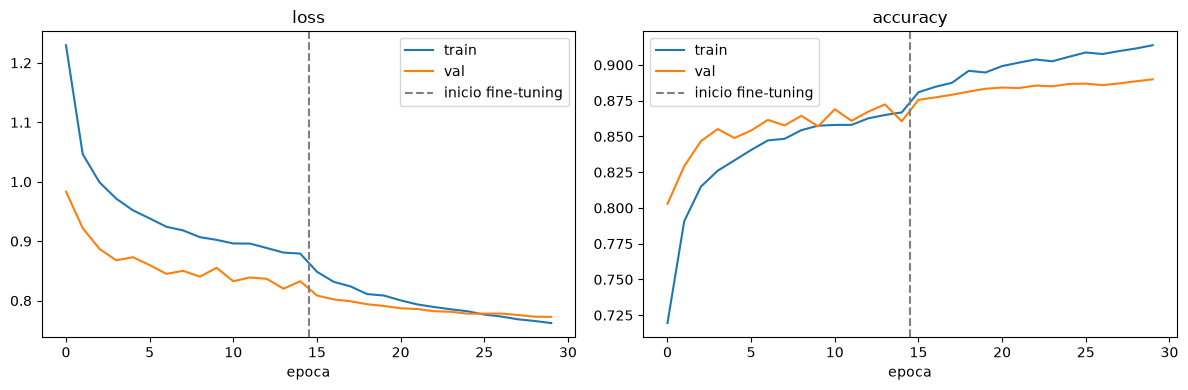

In [7]:
# Celda 7: entrenamiento fase 2 (fine-tuning)
# Igual que la v2: descongela el ultimo 20% de EfficientNet (sin las
# BatchNormalization) y sigue con learning rate 1e-5. Despues carga el
# mejor modelo de las dos fases y grafica las curvas.

base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.8)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss=perdida, metrics=["accuracy"])
history_fine = model.fit(train_ds, validation_data=val_ds, epochs=15,
                         class_weight=class_weights, callbacks=callbacks)

model = tf.keras.models.load_model(MODEL_PATH)
print(f"cargado el mejor modelo desde {MODEL_PATH}")

hist = {k: history_head.history[k] + history_fine.history[k] for k in history_head.history if k in history_fine.history}
fin_fase1 = len(history_head.history["loss"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist[metrica], label="train")
    ax.plot(hist[f"val_{metrica}"], label="val")
    ax.axvline(fin_fase1 - 0.5, color="gray", linestyle="--", label="inicio fine-tuning")
    ax.set_title(metrica)
    ax.set_xlabel("epoca")
    ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# Celda 8: calibracion con temperature scaling (sobre VALIDACION)
# El modelo devuelve probabilidades softmax. Se pasan a log, se dividen
# por una temperatura T y se vuelve a aplicar softmax. Con T > 1 las
# probabilidades se "aflojan" (dejan de estar pegadas a 99 %). La clase
# elegida no cambia. Se elige la T que minimiza la log-loss en validacion.
# Se guarda en CALIB_PATH; el backend la lee.

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def calibrar(probs, t):
    return softmax(np.log(np.clip(probs, 1e-9, 1)) / t)

def log_loss(y, probs):
    return -np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-9, 1)))

val_probs = model.predict(val_ds, verbose=0)
val_true = val_df["label_idx"].values

temperaturas = np.arange(0.5, 4.01, 0.05)
perdidas = [log_loss(val_true, calibrar(val_probs, t)) for t in temperaturas]
T = float(temperaturas[int(np.argmin(perdidas))])

with open(CALIB_PATH, "w") as f:
    json.dump({"temperatura": round(T, 3)}, f, indent=2)
print(f"Temperatura: {T:.2f} | guardada en {CALIB_PATH}")

Temperatura: 0.65 | guardada en ../../models/modelo_clasificacion3_calibracion.json


accuracy en test: 0.888
ECE sin calibrar: 0.077 | calibrado: 0.030
confianza promedio sin calibrar: 81.1% | calibrada: 91.0%

                             precision    recall  f1-score   support

           Structural crack      0.938     0.948     0.943      1001
Surface flaking/exfoliation      0.987     0.621     0.762      1000
            Salt weathering      0.928     0.906     0.917       372
      Material loss/erosion      0.800     0.792     0.796       202
      Moisture/water damage      0.972     0.949     0.961       552
          Biological growth      0.870     0.845     0.857       206
                  Corrosion      0.965     0.953     0.959       991
          Concrete spalling      0.858     0.933     0.894       299
                 Vegetation      0.995     0.985     0.990       747
               Delamination      0.493     0.965     0.653       402
                  Vandalism      0.993     0.987     0.990       153

                   accuracy                 

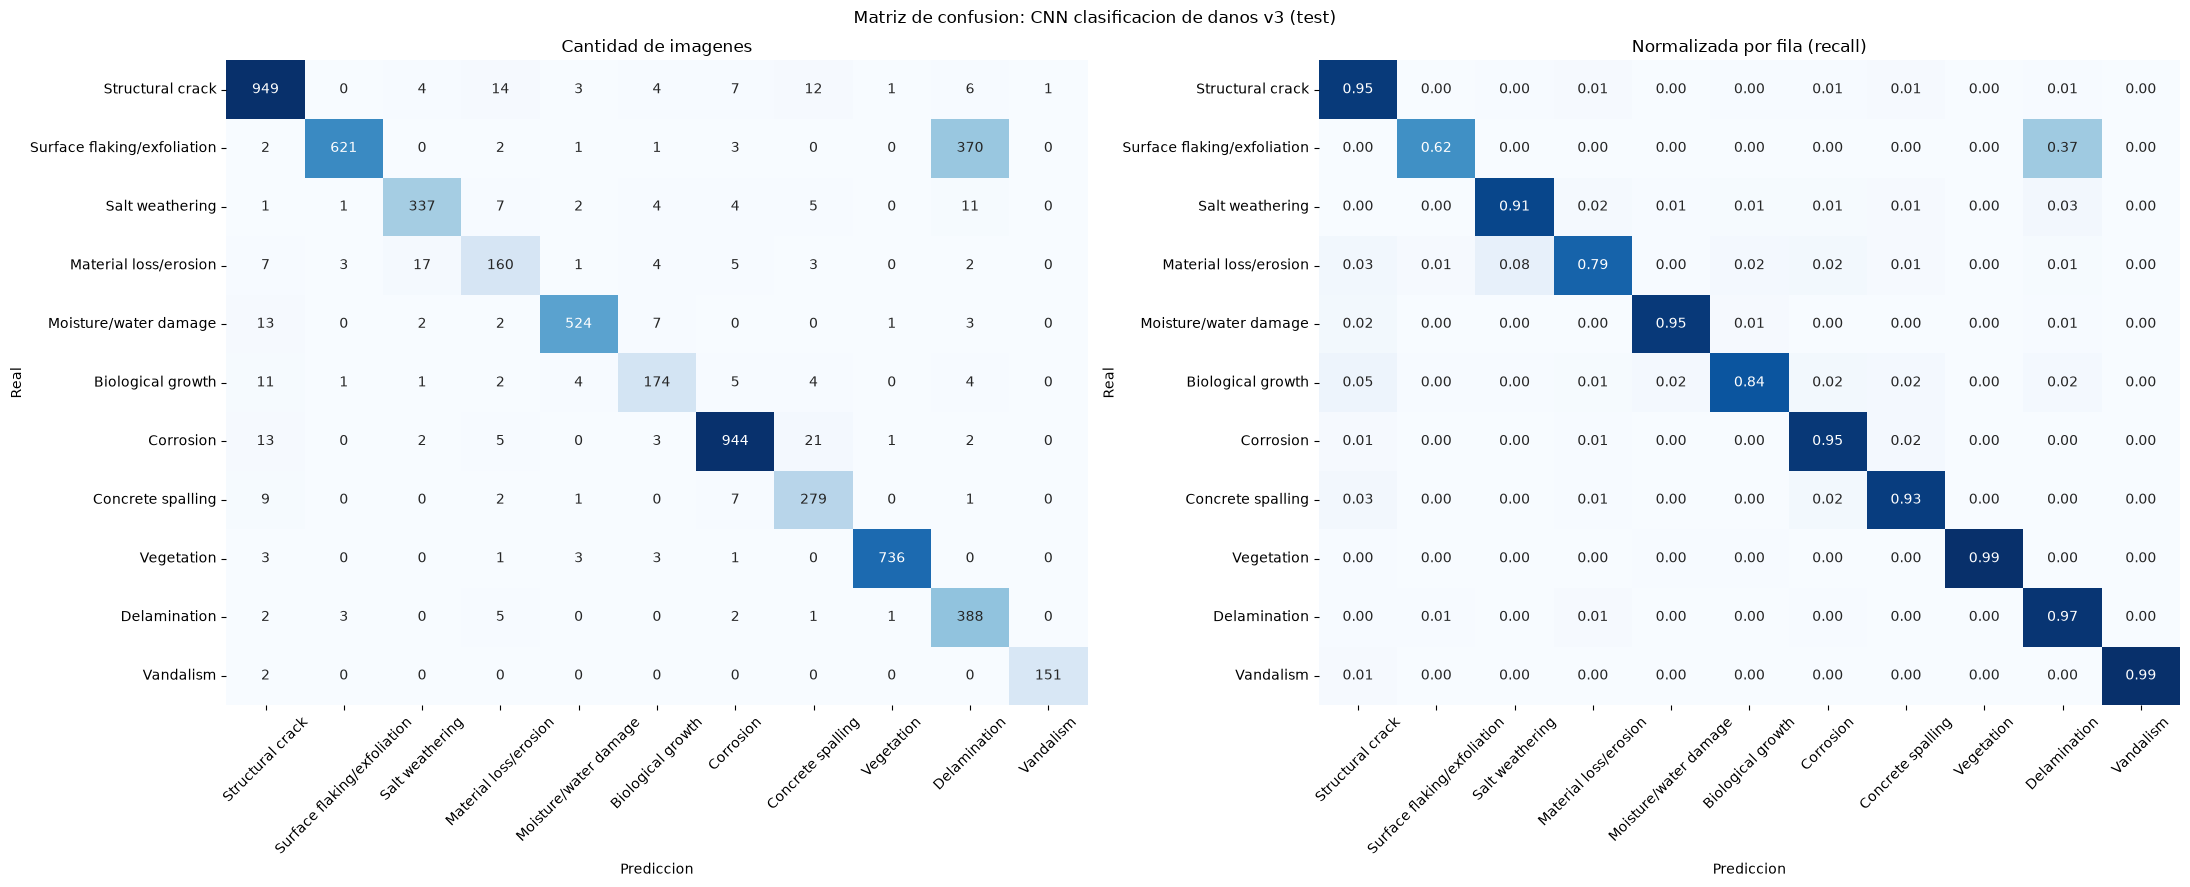

In [9]:
# Celda 9: evaluacion final en test
# Se corre UNA sola vez, con el modelo ya decidido. Muestra accuracy,
# reporte por clase, matriz de confusion y el ECE (error de calibracion:
# cuanto se aleja la confianza que muestra el modelo del % real de
# aciertos; mas bajo es mejor) antes y despues de calibrar.

def ece(probs, y, bins=10):
    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    bordes = np.linspace(0, 1, bins + 1)
    total = 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (conf > a) & (conf <= b)
        if m.any():
            total += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return total

test_probs_crudo = model.predict(test_ds, verbose=0)
test_probs = calibrar(test_probs_crudo, T)
test_pred = test_probs.argmax(axis=1)
test_true = test_df["label_idx"].values

print(f"accuracy en test: {(test_pred == test_true).mean():.3f}")
print(f"ECE sin calibrar: {ece(test_probs_crudo, test_true):.3f} | calibrado: {ece(test_probs, test_true):.3f}")
print(f"confianza promedio sin calibrar: {test_probs_crudo.max(axis=1).mean():.1%} | calibrada: {test_probs.max(axis=1).mean():.1%}\n")
print(classification_report(test_true, test_pred, target_names=FINAL_CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(test_true, test_pred)
cm_norm = confusion_matrix(test_true, test_pred, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=FINAL_CLASSES, yticklabels=FINAL_CLASSES, ax=axes[0], cbar=False)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=FINAL_CLASSES, yticklabels=FINAL_CLASSES, ax=axes[1], cbar=False)
axes[0].set_title("Cantidad de imagenes")
axes[1].set_title("Normalizada por fila (recall)")
for ax in axes:
    ax.set_xlabel("Prediccion")
    ax.set_ylabel("Real")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Matriz de confusion: CNN clasificacion de danos v3 (test)")
plt.tight_layout()
plt.savefig("matriz_confusion_clasificacion3.png", dpi=150)
plt.show()

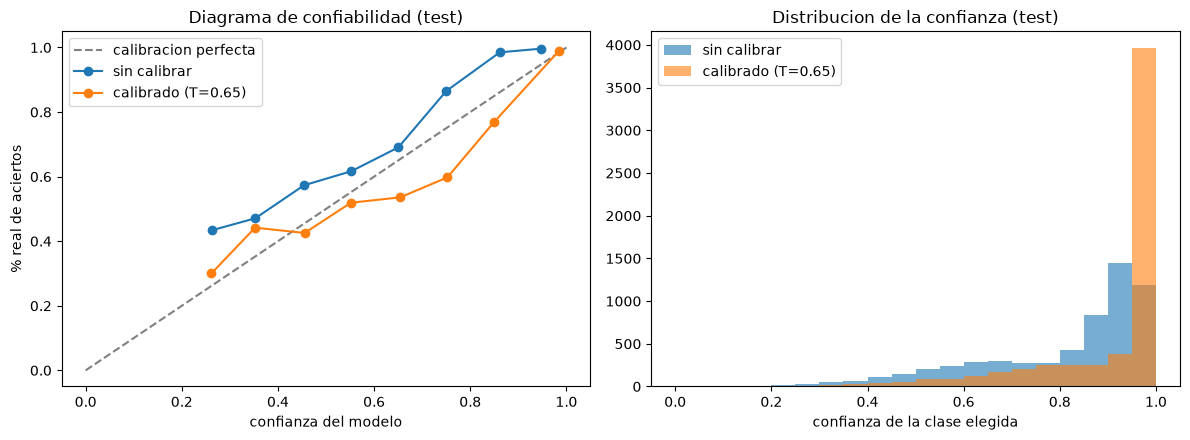

In [10]:
# Celda 10: diagrama de confiabilidad
# Para cada rango de confianza (ej. 70-80 %) compara la confianza promedio
# con el % real de aciertos. Si el modelo esta bien calibrado, los puntos
# quedan sobre la diagonal. Tambien muestra el histograma de confianzas.

def curva(probs, y, bins=10):
    conf = probs.max(axis=1)
    acierto = probs.argmax(axis=1) == y
    bordes = np.linspace(0, 1, bins + 1)
    xs, ys = [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (conf > a) & (conf <= b)
        if m.sum() >= 10:
            xs.append(conf[m].mean())
            ys.append(acierto[m].mean())
    return xs, ys

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="calibracion perfecta")
for probs, nombre in [(test_probs_crudo, "sin calibrar"), (test_probs, f"calibrado (T={T:.2f})")]:
    xs, ys = curva(probs, test_true)
    axes[0].plot(xs, ys, "o-", label=nombre)
    axes[1].hist(probs.max(axis=1), bins=20, range=(0, 1), alpha=0.6, label=nombre)
axes[0].set_xlabel("confianza del modelo")
axes[0].set_ylabel("% real de aciertos")
axes[0].set_title("Diagrama de confiabilidad (test)")
axes[0].legend()
axes[1].set_xlabel("confianza de la clase elegida")
axes[1].set_title("Distribucion de la confianza (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [11]:
# Celda 11: guardar clases y grupos
# El modelo ya quedo guardado por el checkpoint. Se guardan al lado la
# lista de clases (orden de las salidas) y los grupos, con nombre v3.

with open("../../models/modelo_clasificacion3_clases.json", "w") as f:
    json.dump(FINAL_CLASSES, f, indent=2, ensure_ascii=False)
with open("../../models/modelo_clasificacion3_grupos.json", "w") as f:
    json.dump(GRUPOS_FINAL, f, indent=2, ensure_ascii=False)
print(f"modelo en {MODEL_PATH}, calibracion en {CALIB_PATH}, clases y grupos en ../../models/")

modelo en ../../models/modelo_clasificacion3.keras, calibracion en ../../models/modelo_clasificacion3_calibracion.json, clases y grupos en ../../models/
